In [1]:
def kmeans_numpy(X, K, max_iter=100, tol=1e-6):
    n_samples = X.shape[0]
    random_indices = np.random.choice(n_samples, K, replace=False)
    centroids = X[random_indices]
    J_history = []
    
    for iteration in range(max_iter):
        d2 = (X**2).sum(axis=1, keepdims=True) - 2 * np.dot(X, centroids.T) + (centroids**2).sum(axis=1)
        labels = np.argmin(d2, axis=1)
        J = np.sum(np.min(d2, axis=1))
        J_history.append(J)
        
        if iteration > 0 and (J_history[-2] - J) < tol:
            break
            
        new_centroids = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] for j in range(K)])
        centroids = new_centroids
        
    return labels, centroids, J_history

/storage/brno2/home/matyztul/envs/mvd_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0 ['album' 'song' 'songs' 'band' 'released' 'rock']
1 ['deaths' 'births' 'politician' 'died' 'politicians' 'party']
2 ['football' 'league' 'team' 'player' 'rowspan' 'played']
3 ['county' 'states' 'united' 'cities' 'city' 'census']
4 ['used' 'species' 'called' 'usually' 'frog' 'like']
5 ['india' 'indian' 'pakistan' 'province' 'district' 'capital']
6 ['movies' 'movie' 'american' 'actors' 'directed' 'television']
7 ['commune' 'communes' 'france' 'department' 'municipality' 'region']


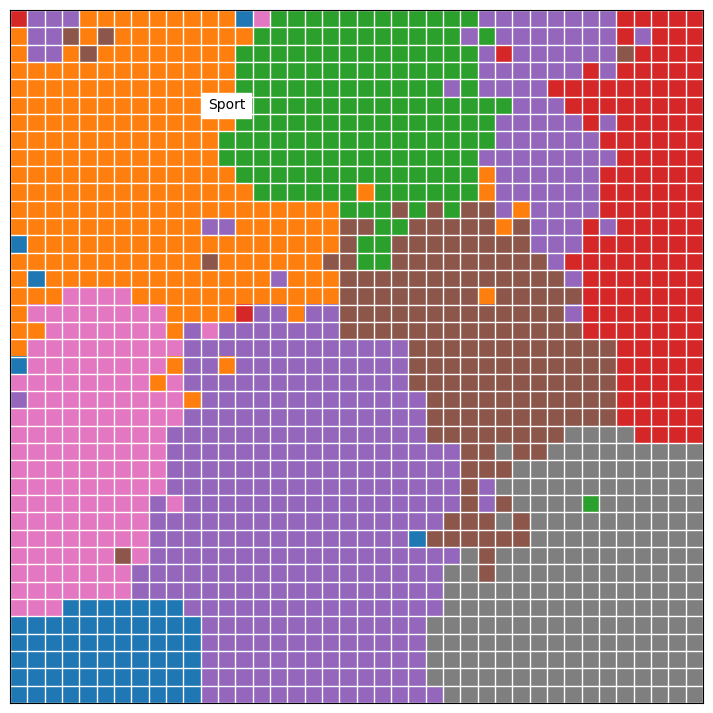

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer

X = np.load("wiki_embeddings.npy").astype(np.float32)     # 241 787 x 384
W = np.load("som_W.npy")                           # 1600 x 384

wiki = load_dataset("wikimedia/wikipedia", "20231101.simple", split="train")
titles, texty = wiki["title"], wiki["text"]

d2 = (X ** 2).sum(1, keepdims=True) - 2 * X @ W.T + (W ** 2).sum(1)   # ‖x − w‖² = ‖x‖² − 2 x·w + ‖w‖²
clanek_neuron = d2.argmin(1)
vzdalenost = np.sqrt(np.maximum(d2.min(1), 0))
pocty = np.bincount(clanek_neuron, minlength=len(W))

best_J = float('inf')
oblast_neuronu = None

for _ in range(10):
    labels, centroids, history = kmeans_numpy(W, K=8)
    if history[-1] < best_J:
        best_J = history[-1]
        oblast_neuronu = labels

tf = TfidfVectorizer(stop_words="english", min_df=20, max_df=0.2, sublinear_tf=True)
M = tf.fit_transform([f"{t}. {x[:600]}" for t, x in zip(titles, texty)])
slova = tf.get_feature_names_out()
vse = M.mean(axis=0).A1
oblast_clanku = oblast_neuronu[clanek_neuron]
for k in range(8):
    skore = M[oblast_clanku == k].mean(axis=0).A1 - vse
    print(k, slova[skore.argsort()[::-1][:6]])

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(oblast_neuronu.reshape(40, 40), cmap="tab10", vmin=0, vmax=9)
ax.set_xticks(np.arange(-0.5, 40), minor=True)
ax.set_yticks(np.arange(-0.5, 40), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
ax.text(12, 5, "Sport", ha="center", va="center", backgroundcolor="white")   # sloupec, řádek, název; souřadnice jsou jen příklad
# ... stejný řádek pro každou další oblast
fig.savefig("som_wiki_mapa.png", dpi=110)

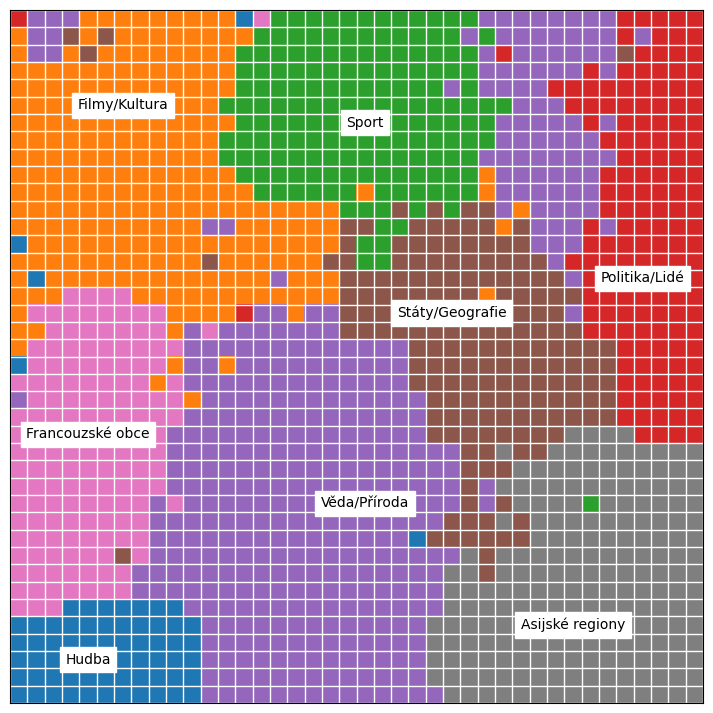

In [4]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(oblast_neuronu.reshape(40, 40), cmap="tab10", vmin=0, vmax=9)
ax.set_xticks(np.arange(-0.5, 40), minor=True)
ax.set_yticks(np.arange(-0.5, 40), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)

ax.text(4, 37, "Hudba", ha="center", va="center", backgroundcolor="white")            
ax.text(36, 15, "Politika/Lidé", ha="center", va="center", backgroundcolor="white")   
ax.text(20, 6, "Sport", ha="center", va="center", backgroundcolor="white")
ax.text(25, 17, "Státy/Geografie", ha="center", va="center", backgroundcolor="white")
ax.text(20, 28, "Věda/Příroda", ha="center", va="center", backgroundcolor="white")   
ax.text(32, 35, "Asijské regiony", ha="center", va="center", backgroundcolor="white") 
ax.text(6, 5, "Filmy/Kultura", ha="center", va="center", backgroundcolor="white")     
ax.text(4, 24, "Francouzské obce", ha="center", va="center", backgroundcolor="white") 

fig.savefig("som_wiki_mapa.png", dpi=110)